# **Predicting if a person would buy life insurnace based on his age using logistic regression**
Above is a binary logistic regression problem as there are only two possible outcomes (i.e. if person buys insurance or he/she doesn't).

In [1]:
#Import libraries
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [2]:
df = pd.read_csv("/content/insurance_data.csv")
df

,age,bought_insurance
0,22,0
1,25,0
2,47,1
3,52,0
4,46,1
5,56,1
6,55,0
7,60,1
8,62,1
9,61,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   age               27 non-null     int64
 1   bought_insurance  27 non-null     int64
dtypes: int64(2)
memory usage: 564.0 bytes


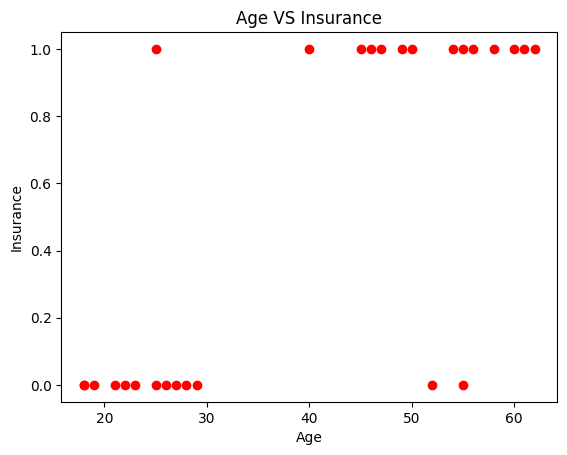

In [4]:
plt.scatter(df.age,df.bought_insurance,color='red',marker='o')
plt.title("Age VS Insurance")
plt.xlabel("Age")
plt.ylabel("Insurance")
plt.show()

In [5]:
X=df.drop(columns=['bought_insurance'])
y=df['bought_insurance']

In [6]:
X

,age
0,22
1,25
2,47
3,52
4,46
5,56
6,55
7,60
8,62
9,61


In [7]:
y

,bought_insurance
0,0
1,0
2,1
3,0
4,1
5,1
6,0
7,1
8,1
9,1


In [9]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state =90)

In [10]:
X_train

,age
1,25
15,55
23,45
12,27
8,62
20,21
17,58
19,18
9,61
2,47


In [11]:
y_train

,bought_insurance
1,0
15,1
23,1
12,0
8,1
20,0
17,1
19,0
9,1
2,1


In [12]:
X_test

,age
21,26
6,55
24,50
22,40
25,54
14,49


In [13]:
y_test

,bought_insurance
21,0
6,0
24,1
22,1
25,1
14,1


In [14]:
model = LogisticRegression()

In [15]:
model.fit(X_train, y_train)

LogisticRegression()

In [16]:
y_predicted = model.predict(X_test)
y_predicted

array([0, 1, 1, 1, 1, 1])

In [17]:
pd.DataFrame({'y_test':y_test,'y_predict':y_predicted})

,y_test,y_predict
21,0,0
6,0,1
24,1,1
22,1,1
25,1,1
14,1,1


In [18]:
model.predict([[70]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([1])

In [19]:
model.coef_

array([[0.15234884]])

In [20]:
model.intercept_

array([-5.84806651])

# **Lets defined sigmoid function now and do the math with hand**

In [26]:
#sigmoid function
import math
def sigmoid(x):
  return 1 / (1 + math.exp(-x))
def prediction_function(age):
    z = 0.15234884 * age + (-5.84806651)
    y = sigmoid(z)
    return y
age = 35
prediction_function(age)
#0.373 is less than 0.5 which means person with 35 age will not buy insurance

0.37382148910782037

In [24]:
age = 43
prediction_function(age)
#0.668 is more than 0.5 which means person with 43 will buy the insurance

0.6688378700475973